# Лабораторная работа №2 — вариант 2
## Pandas и основы Python

**Вариант 2:** \(y = \cos(x_1 + x_2)\).

В работе генерируется таблица из более чем 400 строк, сохраняется в CSV, затем данные повторно загружаются, анализируются и визуализируются.


## 1. Импорт библиотек

Используем `pandas` для таблиц, `numpy` для вычисления функции и создания сетки значений, а `matplotlib` — для графиков.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D  # поддержка 3D-графиков


## 2. Генерация данных и сохранение CSV

Диапазон каждой переменной выбран от \(-2\pi\) до \(2\pi\). `linspace` формирует по 25 значений для каждой переменной. Их декартово произведение даёт 25 × 25 = 625 строк, что больше требуемых 400.

Функция варианта: \(y = \cos(x_1+x_2)\).


In [2]:
# наборы значений x1 и x2
x1_values = np.linspace(-2 * np.pi, 2 * np.pi, 25)
x2_values = np.linspace(-2 * np.pi, 2 * np.pi, 25)

# сетка всех сочетаний
X1, X2 = np.meshgrid(x1_values, x2_values)

Y = np.cos(X1 + X2)

#  DataFrame
data = pd.DataFrame({
    'x1': X1.ravel(),
    'x2': X2.ravel(),
    'y': Y.ravel()
})

# Сохранение данных
data.to_csv('lab02_variant2.csv', index=False)

print(f'Количество строк: {len(data)}')
print(data.head())


Количество строк: 625
         x1        x2             y
0 -6.283185 -6.283185  1.000000e+00
1 -5.759587 -6.283185  8.660254e-01
2 -5.235988 -6.283185  5.000000e-01
3 -4.712389 -6.283185 -4.286264e-16
4 -4.188790 -6.283185 -5.000000e-01


## 3. Чтение CSV-файла



In [3]:
data = pd.read_csv('lab02_variant2.csv')
print('Размер таблицы:', data.shape)
data.head()


Размер таблицы: (625, 3)


,x1,x2,y
0,-6.283185,-6.283185,1.000000e+00
1,-5.759587,-6.283185,8.660254e-01
2,-5.235988,-6.283185,5.000000e-01
3,-4.712389,-6.283185,-4.286264e-16
4,-4.188790,-6.283185,-5.000000e-01


## 4. Графики y(x1) и y(x2)

Для графика \(y(x_1)\) фиксируем \(x_2=0\), а для графика \(y(x_2)\) фиксируем \(x_1=0\). Используем точки, чтобы показать отдельные значения функции.


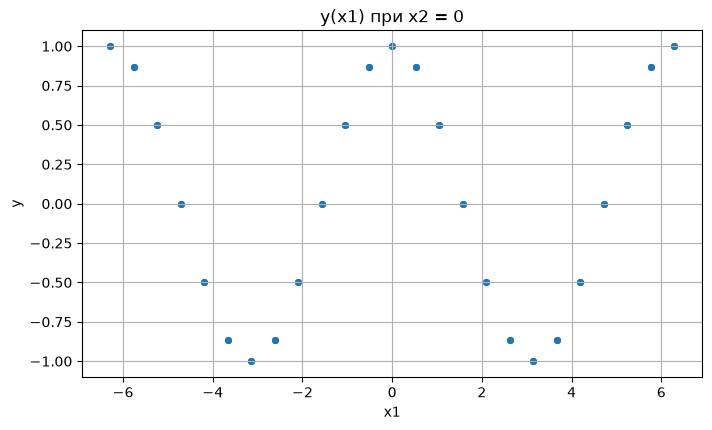

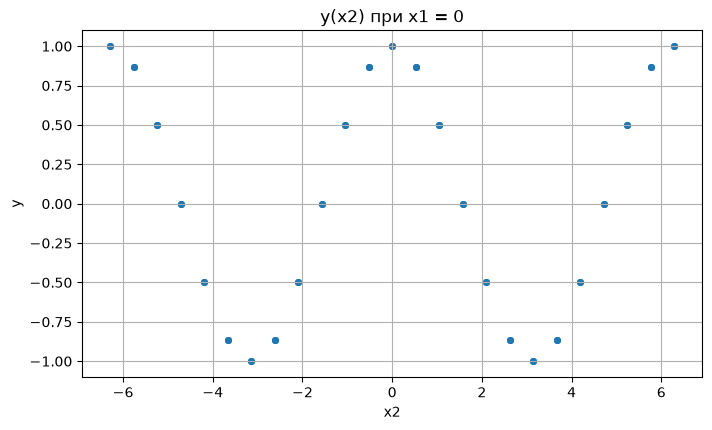

In [4]:
# y(x1), когда x2 = 0
x2_const = 0.0
y_x1 = np.cos(data['x1'] + x2_const)

plt.figure(figsize=(8, 4.5))
plt.scatter(data['x1'], y_x1, s=12)
plt.title('y(x1) при x2 = 0')
plt.xlabel('x1')
plt.ylabel('y')
plt.grid(True)
plt.show()

# y(x2), когда x1 = 0
x1_const = 0.0
y_x2 = np.cos(x1_const + data['x2'])

plt.figure(figsize=(8, 4.5))
plt.scatter(data['x2'], y_x2, s=12)
plt.title('y(x2) при x1 = 0')
plt.xlabel('x2')
plt.ylabel('y')
plt.grid(True)
plt.show()


## 5. Среднее, минимальное и максимальное значения



In [5]:
stats = data[['x1', 'x2', 'y']].agg(['mean', 'min', 'max']).T
stats.columns = ['Среднее', 'Минимум', 'Максимум']
stats


,Среднее,Минимум,Максимум
x1,-3.979039e-16,-6.283185,6.283185
x2,-5.456968e-16,-6.283185,6.283185
y,1.600000e-03,-1.000000,1.000000


## 6. Фильтрация и сохранение нового CSV

Сохраняем строки, для которых выполняется хотя бы одно условие:
\(x_1 < \overline{x_1}\) **или** \(x_2 < \overline{x_2}\).



In [6]:
mean_x1 = data['x1'].mean()
mean_x2 = data['x2'].mean()

filtered_data = data[
    (data['x1'] < mean_x1) | (data['x2'] < mean_x2)
]

filtered_data.to_csv('lab02_variant2_filtered.csv', index=False)

print('Среднее x1:', mean_x1)
print('Среднее x2:', mean_x2)
print('Строк до фильтрации:', len(data))
print('Строк после фильтрации:', len(filtered_data))
print("Файл сохранён: lab02_variant2_filtered.csv")


Среднее x1: -3.979039320256561e-16
Среднее x2: -5.456968210637569e-16
Строк до фильтрации: 625
Строк после фильтрации: 456
Файл сохранён: lab02_variant2_filtered.csv


## 7. 3D-график функции



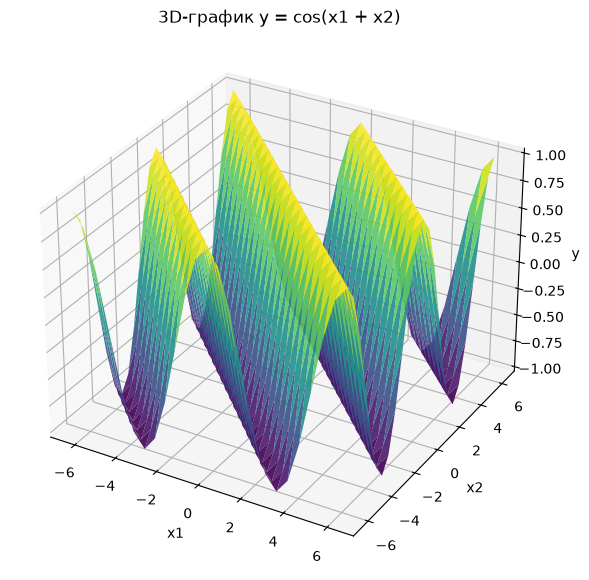

In [7]:
fig = plt.figure(figsize=(10, 7))
ax = fig.add_subplot(111, projection='3d')

ax.plot_surface(X1, X2, Y, cmap='viridis', edgecolor='none', alpha=0.9)

ax.set_title('3D-график y = cos(x1 + x2)')
ax.set_xlabel('x1')
ax.set_ylabel('x2')
ax.set_zlabel('y')

plt.show()


## Вывод

В ходе лабораторной работы для варианта 2 сгенерирована таблица из 625 строк со значениями \(x_1\), \(x_2\) и \(y=\cos(x_1+x_2)\). Данные сохранены в CSV и повторно загружены средствами pandas. Построены двумерные графики функции при фиксировании одной переменной и трёхмерная поверхность. Для каждого столбца рассчитаны среднее, минимальное и максимальное значения. Также выполнена фильтрация строк по условию \(x_1 < \overline{x_1}\) или \(x_2 < \overline{x_2}\), а результат сохранён в отдельный CSV-файл.
